### this script calculate the topic similarity between international and non-international collaborated papers by **authorship**

In [1]:
import pandas as pd
import numpy as np
import itertools
from multiprocessing import Pool
from tqdm import tqdm
from scipy.spatial import distance
import random
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"

In [3]:
embedding_file = np.load(embedding_path)
embedding = embedding_file['emb']
uids = embedding_file['uids']

In [4]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

In [5]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [6]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

In [7]:
path = "../../data/dropbox/LaborDivision/data/additionaldata/list_discipline.txt"
dis_df = pd.read_csv(path,sep="|", on_bad_lines='skip')
dis_map = dict(zip(dis_df['Code_Discipline'],dis_df['EDiscipline']))

In [8]:
pub_all = pub_all.replace(to_replace={'dis':dis_map})

### create an dict which records uid and the index in uids array to derive the embedding from the embedding array

In [9]:
uid_index_dict={}
n = 0
for uid in tqdm(uids):
    uid_index_dict[uid]=n
    n=n+1

100%|███████████████████████████| 84162157/84162157 [01:39<00:00, 841672.60it/s]


#### select papers that are **internationally authored** and **nonalphabetically** ordered

In [10]:
pub_all.head()

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
0,29768068,40806321.0,CAN,F,2008,Clinical Medicine,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
1,29768068,41639269.0,CAN,M,2008,Clinical Medicine,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
2,29768068,53722752.0,CAN,L,2008,Clinical Medicine,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
3,29768070,65683243.0,JPN,F,2008,Clinical Medicine,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012
4,29768070,79129017.0,JPN,M,2008,Clinical Medicine,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012


In [11]:
pub_dome = pub_all[pub_all.intl==0][['uid','cntry','dis']].drop_duplicates()
pub_dome['type'] = 'dome'
pub_dome.head(2)

,uid,cntry,dis,type
0,WOS:000259648000022,CAN,Clinical Medicine,dome
8,WOS:000261972700004,RUS,Chemistry,dome


In [12]:
pub_intl = pub_all[(pub_all.intl==1)&(pub_all.alpha=='noalp')][['uid','cntry','dis','role']].drop_duplicates()

In [13]:
pub_intl['type'] = pub_intl.apply(lambda x:'L' if x.role in ['F','L'] else "S", axis=1)

In [14]:
pub_intl = pub_intl.drop(columns=['role'])
pub_intl = pub_intl.drop_duplicates()

In [15]:
pub_intl['type_count']=pub_intl.groupby(['uid','cntry','dis'])['type'].transform('nunique')

In [16]:
mask = ((pub_intl['type_count']==1)|((pub_intl['type_count']==2) & (pub_intl['type']=='L')))

In [17]:
pub_intl = pub_intl[mask]

In [18]:
pub_intl = pub_intl.drop(columns=['type_count'])

In [19]:
pub_dome.head(2)

,uid,cntry,dis,type
0,WOS:000259648000022,CAN,Clinical Medicine,dome
8,WOS:000261972700004,RUS,Chemistry,dome


In [20]:
pub_filtered = pd.concat([pub_dome, pub_intl])
pub_filtered.head()

,uid,cntry,dis,type
0,WOS:000259648000022,CAN,Clinical Medicine,dome
8,WOS:000261972700004,RUS,Chemistry,dome
10,WOS:000266456400005,RUS,Chemistry,dome
16,WOS:000253582400009,CHN,Biomedical Research,dome
26,WOS:000253179500020,CHN,Chemistry,dome


### create a dict to record publications at country-discipline level with distinguish domestic, international-leading, international-supporting publications

In [21]:
cntry_dis_dict = {}
cntry_dis_arrays = pub_filtered[['cntry','dis','type','uid']].values
for row in tqdm(cntry_dis_arrays):
    cntry = row[0]
    dis = row[1]
    ptype = row[2]
    uid = row[3]
    
    # Check if the key_A already exists in the nested dictionary
    if (cntry,dis) in cntry_dis_dict:
        # Check if the key_B already exists for the key_A
        if ptype in cntry_dis_dict[(cntry,dis)]:
            # Append the value_C to the existing list
            cntry_dis_dict[(cntry,dis)][ptype].append(uid)
        else:
            # Create a new key_B entry with a list containing value_C
            cntry_dis_dict[(cntry,dis)][ptype] = [uid]
    else:
        # Create a new key_A entry with a nested dictionary containing key_B and value_C
        cntry_dis_dict[(cntry,dis)] = {ptype: [uid]}

100%|███████████████████████████| 20878502/20878502 [00:30<00:00, 691870.85it/s]


### calculate the distance between sets of papers

In [22]:
def return_embeddings(pubs,uid_index_dict,embedding):
    embed_index = [uid_index_dict[uid] for uid in pubs if uid in uid_index_dict]
    if embed_index:
        embed_vectors = embedding[embed_index]
        return embed_vectors
    return None

In [23]:
def precompute_raw_embeddings(cntry_dist_dict, uid_index_dict, embedding):
    embeddings_raw = {}
    for cntry_dis, ptype_uids in cntry_dis_dict.items():
        embeddings_raw[cntry_dis]={}
        for ptype, uids in ptype_uids.items():
            emb = return_embeddings(uids, uid_index_dict, embedding)
            embeddings_raw[cntry_dis][ptype]=emb
    return embeddings_raw

In [24]:
cntry_dis_embed_raw = precompute_raw_embeddings(cntry_dis_dict, uid_index_dict, embedding)

In [25]:
def sample_embeddings(cntry_dis_emb_raw, minimum_size=10, sample_size=50):
    embeddings_sample = {}
    for cntry_dis, intl_embeds in cntry_dis_emb_raw.items():
        embeddings_sample[cntry_dis]={}
        for intl, embeds in intl_embeds.items():
            if embeds is not None and embeds.shape[0]> minimum_size:
                resampled_indices = np.random.choice(len(embeds), size=sample_size, replace=True)
                embeddings_sample[cntry_dis][intl] = embeds[resampled_indices]
    return embeddings_sample

In [26]:
def cal_similarity(cntry_dis_embedding):
    results=[]
    for cntry_dis, pubs in cntry_dis_embedding.items():
        embed_dome = pubs.get('dome')
        embed_support = pubs.get('S')
        embed_leading = pubs.get('L')

        if embed_dome is not None and embed_support is not None and embed_leading is not None:
            distance_support = 1-distance.cosine(np.mean(embed_dome,axis=0), np.mean(embed_support,axis=0))
            distance_leading = 1-distance.cosine(np.mean(embed_dome,axis=0), np.mean(embed_leading,axis=0))

            results.append([cntry_dis[0], cntry_dis[1], 'support', distance_support])
            results.append([cntry_dis[0], cntry_dis[1], 'leading', distance_leading])
    results = pd.DataFrame(results, columns=['cntry','dis','type','similarity'])
    return results


In [27]:
cntry_dis_embed_raw = precompute_raw_embeddings(cntry_dis_dict, uid_index_dict, embedding)
cntry_similarity_raw = cal_similarity(cntry_dis_embed_raw)

In [28]:
iteration_num = 100
cntry_similarity_sampled = pd.DataFrame()
for _ in tqdm(range(iteration_num)):
    embeds_sampled = sample_embeddings(cntry_dis_embed_raw)
    sampled_res = cal_similarity(embeds_sampled)
    cntry_similarity_sampled = pd.concat([cntry_similarity_sampled, sampled_res])

100%|█████████████████████████████████████████| 100/100 [00:39<00:00,  2.50it/s]


In [29]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','class']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'class':{'Others':'Lagging'}})
stgroup_df.head()

,Code,class
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [30]:
color_scheme_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/color_scheme.csv'
color_scheme = pd.read_csv(color_scheme_path)
color_scheme = color_scheme[color_scheme['type']=='st']
color_dict = dict(zip(color_scheme['class'], color_scheme['color']))

In [31]:
def merge_with_group(df, group_df):
    df = df.merge(group_df, left_on='cntry', right_on='Code')
    df = df.groupby(['cntry','class','type'])['similarity'].mean().reset_index()
    return df

In [32]:
cntry_similarity_raw

,cntry,dis,type,similarity
0,CAN,Clinical Medicine,support,0.987549
1,CAN,Clinical Medicine,leading,0.998601
2,RUS,Chemistry,support,0.990495
3,RUS,Chemistry,leading,0.995251
4,CHN,Biomedical Research,support,0.969484
...,...,...,...,...
4071,MDA,Professional Fields,leading,0.957965
4072,HND,Earth and Space,support,0.630619
4073,HND,Earth and Space,leading,0.340771
4074,GNB,Health,support,0.887450


In [33]:
group_similarity_raw = merge_with_group(cntry_similarity_raw, stgroup_df)

In [34]:
def plot(df, order):
    color_dict={}
    color_dict['leading']='#319DEF'
    color_dict['support']='#EDB44C'
    
    fig, ax=plt.subplots()
    sns.stripplot(x='class',y='similarity',data=df, hue='type', ax=ax, order=order,dodge=True, alpha=0.9, legend=False, palette=color_dict)
    sns.boxplot(x='class',y='similarity',data=df, hue='type',
                boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
                medianprops={'color':'#A7A7A7'},
                whiskerprops={'color':'#A7A7A7'},
                capprops={'color':'#A7A7A7'},
                order=order,
                fliersize=0,
                ax=ax)


    ax.set_ylabel("Publication similarity by authorship", fontsize=12)
    ax.set_xlabel("")
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    legend_markers = [plt.Line2D([0], [0], marker='o', color=color_dict['leading'], markerfacecolor=color_dict['leading'], markersize=8),
                      plt.Line2D([0], [0], marker='o', color=color_dict['support'], markerfacecolor=color_dict['support'], markersize=8)]
    plt.legend(legend_markers, ['Leading', 'Supporting'], fontsize=12, frameon=False, loc='lower left')
    return fig, ax

In [77]:
def p_value_to_label(p_value):
    if p_value < 0.001:
        return "***"
    elif p_value < 0.01:
        return "**"
    elif p_value < 0.05:
        return "*"
    elif p_value < 0.1:
        return "+"
    else:
        return "ns"  # Not significant
def annotate_significance(df, order, ax, yshift, height):
    for i, cls in enumerate(order):
        leading = df[(df['class'] == cls) & (df['type'] == 'leading')]['similarity']
        support = df[(df['class'] == cls) & (df['type'] == 'support')]['similarity']

        # Perform the t-test
        t_stat, p_value = stats.ttest_rel(leading, support, alternative='greater')
        label = p_value_to_label(p_value)

        # Get the x-position of the two boxes (leading and support)
        x1, x2 = i - 0.2, i + 0.2  # Adjusted to align with dodge=True
        y, h = df['similarity'].max() + yshift, height  # Adjust height for significance annotation

        # Plot the significance line
        ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c='k')
        ax.text((x1 + x2) * 0.5, y + h, label, ha='center', va='bottom', color='k')
    return ax

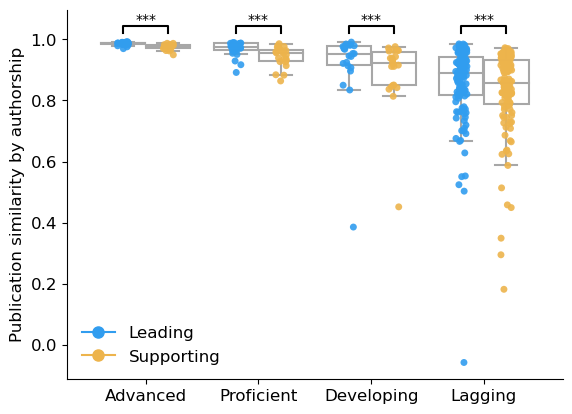

In [80]:
group_similarity_raw = merge_with_group(cntry_similarity_raw, stgroup_df)
fig, ax = plot(group_similarity_raw, color_dict.keys())
annotate_significance(group_similarity_raw, list(color_dict.keys()), ax, 0.03, 0.02)
plt.savefig('../../data/dropbox/LaborDivision/figs/pub_similarity_derived_by_authorship.pdf',bbox_inches='tight')

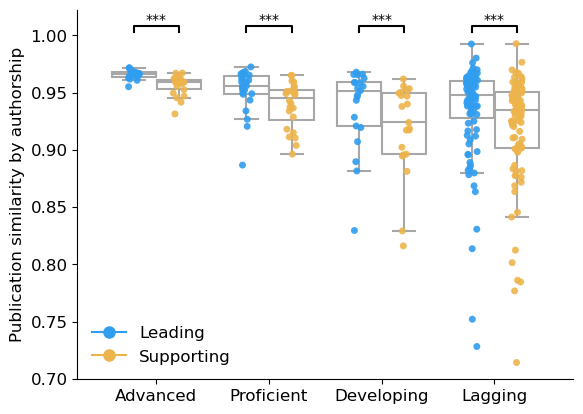

In [82]:
group_similarity_sampled = merge_with_group(cntry_similarity_sampled,stgroup_df)
fig, ax = plot(group_similarity_sampled, color_dict.keys())
annotate_significance(group_similarity_sampled, list(color_dict.keys()), ax,0.01,0.005)
plt.savefig('../../data/dropbox/LaborDivision/figs/pub_similarity_derived_by_authorship_sampled.pdf',bbox_inches='tight')